In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout

C:\Users\nagap\anaconda3\New folder\envs\major\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
# Directory for dataset
directory = "dataset"

In [3]:
# Image data loading
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    directory,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(224, 224),
    shuffle=True,
    seed=24,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=True
)

Found 383 files belonging to 2 classes.


['Defective', 'Non_Defective']


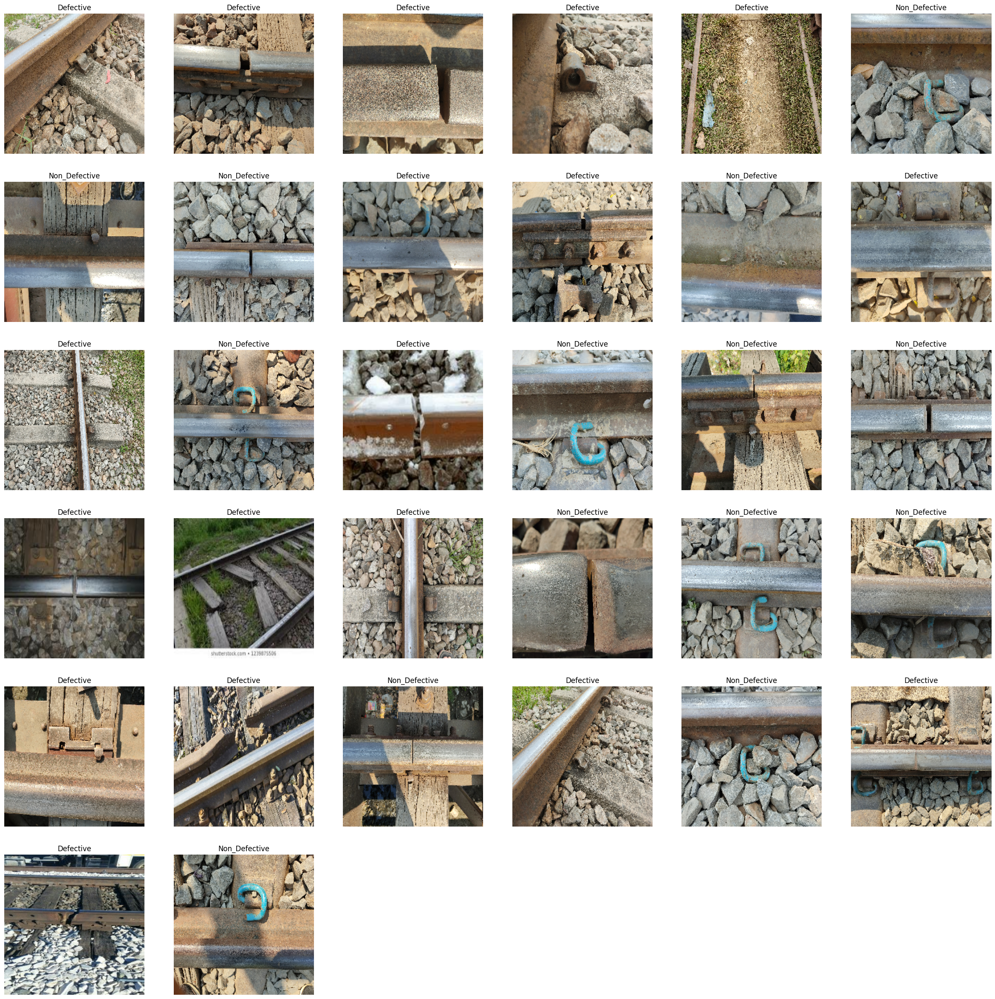

In [4]:
# Display sample images from the dataset
plt.figure(figsize=(30, 30))
class_names = train_ds.class_names
print(class_names)

for images, labels in train_ds.take(2):
    for i in range(32):
        ax = plt.subplot(6, 6, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        class_label_index = int(np.argmax(labels[i]))
        plt.title(class_names[class_label_index])
        plt.axis("off")

plt.show()

In [5]:
# Enable loading truncated images
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

In [6]:
# Data augmentation
datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    rotation_range=30,
    validation_split=0.3,
    fill_mode='nearest'
)

In [7]:
# Train data iterator
train_it = datagen.flow_from_directory(
    directory,
    class_mode='categorical',
    target_size=(224, 224),
    batch_size=100,
    subset='training',
    seed=24
)

Found 269 images belonging to 2 classes.


In [8]:
# Validation data iterator
val_it = datagen.flow_from_directory(
    directory,
    class_mode='categorical',
    target_size=(224, 224),
    batch_size=100,
    subset='validation',
    seed=24
)

Found 114 images belonging to 2 classes.


In [9]:
# Load MobileNetV2 base model without top layers
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

9406464/9406464 [==============================] - 1s 0us/step


In [10]:
# Freeze the layers of the base model
for layer in base_model.layers:
    layer.trainable = False

In [11]:
# Add custom classification layers on top of the base model
x = base_model.output
x = Dropout(0.5)(x)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)

In [12]:
# Create the model with MobileNetV2 as the base
model = Model(inputs=base_model.input, outputs=predictions)

In [13]:
# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [14]:
# Model summary
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 Conv1 (Conv2D)              (None, 112, 112, 32)         864       ['input_1[0][0]']             
                                                                                                  
 bn_Conv1 (BatchNormalizati  (None, 112, 112, 32)         128       ['Conv1[0][0]']               
 on)                                                                                              
                                                                                                  
 Conv1_relu (ReLU)           (None, 112, 112, 32)         0         ['bn_Conv1[0][0]']        

In [15]:
# Train the model
history = model.fit(train_it, epochs=50, validation_data=val_it)

Epoch 1/50
3/3 [==============================] - 132s 49s/step - loss: 1.1265 - accuracy: 0.4796 - val_loss: 0.8145 - val_accuracy: 0.5439
Epoch 2/50
3/3 [==============================] - 99s 35s/step - loss: 0.7505 - accuracy: 0.5725 - val_loss: 0.8221 - val_accuracy: 0.5526
Epoch 3/50
3/3 [==============================] - 99s 40s/step - loss: 0.5566 - accuracy: 0.6654 - val_loss: 0.7305 - val_accuracy: 0.5263
Epoch 4/50
3/3 [==============================] - 100s 36s/step - loss: 0.5782 - accuracy: 0.6691 - val_loss: 0.6034 - val_accuracy: 0.6667
Epoch 5/50
3/3 [==============================] - 101s 36s/step - loss: 0.4652 - accuracy: 0.7807 - val_loss: 0.6758 - val_accuracy: 0.6140
Epoch 6/50
3/3 [==============================] - 100s 36s/step - loss: 0.4922 - accuracy: 0.7732 - val_loss: 0.7143 - val_accuracy: 0.5702
Epoch 7/50
3/3 [==============================] - 104s 37s/step - loss: 0.4306 - accuracy: 0.7955 - val_loss: 0.6166 - val_accuracy: 0.6667
Epoch 8/50
3/3 [======

In [16]:
# Evaluate the model on validation data
loss, accuracy = model.evaluate(val_it)
print(f'Validation Loss: {loss:.4f}')
print(f'Validation Accuracy: {accuracy:.4f}')

2/2 [==============================] - 29s 2s/step - loss: 0.8933 - accuracy: 0.6579
Validation Loss: 0.8933
Validation Accuracy: 0.6579


In [17]:
# Data generator for testing
test_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.6
)

In [18]:
test_data = test_datagen.flow_from_directory(
    directory,
    target_size=(224, 224),
    batch_size=32,
    shuffle=True,
    class_mode='binary',
    subset='validation'
)

Found 229 images belonging to 2 classes.


In [19]:
# Get the true and predicted labels for the test data
true_labels = test_data.classes
predicted_labels = np.argmax(model.predict(test_data), axis=1)

8/8 [==============================] - 62s 7s/step


In [20]:
# Plot training and validation loss and accuracy
def plot_loss(history):
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper right')
    plt.show()

In [21]:
def plot_accuracy(history):
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='lower right')
    plt.show()

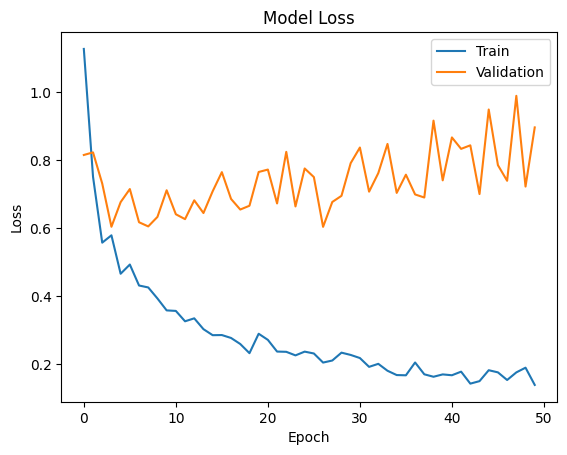

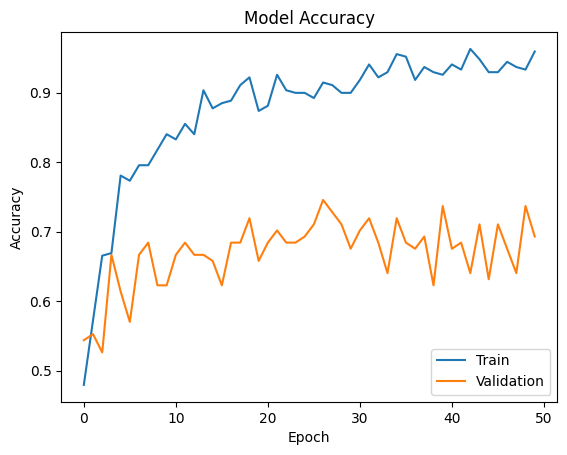

In [22]:
plot_loss(history)
plot_accuracy(history)

In [23]:
# Save the model
model.save("MOBILENET.h5")

C:\Users\nagap\anaconda3\New folder\envs\major\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [24]:
# Print final accuracies
final_train_accuracy = history.history['accuracy'][-1]
final_val_accuracy = history.history['val_accuracy'][-1]
print("Final Accuracy:", final_train_accuracy)
print("Final Validation Accuracy:", final_val_accuracy)

Final Accuracy: 0.9591078162193298
Final Validation Accuracy: 0.6929824352264404


In [25]:
# Evaluate metrics
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

mse = mean_squared_error(true_labels, predicted_labels)
r_squared = r2_score(true_labels, predicted_labels)
mae = mean_absolute_error(true_labels, predicted_labels)

print("Mean Squared Error (MSE):", mse)
print("R-squared:", r_squared)
print("Mean Absolute Error (MAE):", mae)

Mean Squared Error (MSE): 0.4847161572052402
R-squared: -0.9389016018306642
Mean Absolute Error (MAE): 0.4847161572052402


In [26]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from shutil import copy2

# Set paths
test_directory = "dataset"  # Replace with your test dataset path
save_directory = "correctly_classified"  # Replace with desired output folder

# Create the directory if it doesn't exist
os.makedirs(save_directory, exist_ok=True)

# Load the trained model
model = tf.keras.models.load_model("MOBILENET.h5")  # Replace with your model's path

# Target image size for prediction
IMG_SIZE = (224, 224)  # Match the input size used in training

# Get class names from folder structure in the test dataset
class_names = sorted([d for d in os.listdir(test_directory) if os.path.isdir(os.path.join(test_directory, d))])

def predict_and_save_correct_images():
    """Predict each image and save correctly classified ones."""
    total_images = 0
    correct_images = 0

    # Loop through each class folder
    for class_name in class_names:
        class_path = os.path.join(test_directory, class_name)

        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)

            try:
                # Load and preprocess the image
                img = load_img(img_path, target_size=IMG_SIZE)
                img_array = img_to_array(img) / 255.0  # Normalize the image
                img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

                # Predict the class
                prediction = model.predict(img_array, verbose=0)
                predicted_class = np.argmax(prediction[0])

                # Check if prediction matches the folder name (true label)
                if class_names[predicted_class] == class_name:
                    correct_images += 1

                    # Save correctly classified image
                    dest_path = os.path.join(save_directory, class_name)
                    os.makedirs(dest_path, exist_ok=True)  # Create class-specific folder
                    copy2(img_path, dest_path)

                total_images += 1

            except Exception as e:
                print(f"Error processing {img_path}: {e}")

    print(f"Total Images: {total_images}")
    print(f"Correctly Classified Images: {correct_images}")

# Run the prediction and saving process
predict_and_save_correct_images()

Total Images: 384
Correctly Classified Images: 311
